In [1]:
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import numpy as np

# Import our modules
from helpers.scenario_loader import create_instance_from_csv
from helpers.online_wrapper import run_online_scheduling
from helpers.clairvoyant_solution import calculate_true_optimal, calculate_greedy_optimal
from initial import evaluate, construct_schedule

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

## 1. Load Scenarios

In [2]:
# Load both scenarios
normal_inst = create_instance_from_csv(scenario="normal")
earthquake_inst = create_instance_from_csv(scenario="earthquake", failure_scenario="earthquake_moderate")

print("=" * 60)
print("NORMAL DAY SCENARIO")
print("=" * 60)
print(f"Jobs: {len(normal_inst.jobs)}")
print(f"Resources: {len([s for s in normal_inst.servers.values() if not s.is_cloud])} local + {len([s for s in normal_inst.servers.values() if s.is_cloud])} cloud")
print(f"Time Horizon: {normal_inst.time_horizon} hours")
print(f"Machine Failures: {len(normal_inst.machine_failures) if normal_inst.machine_failures else 0}")

print("\n" + "=" * 60)
print("EARTHQUAKE EMERGENCY SCENARIO")
print("=" * 60)
print(f"Jobs: {len(earthquake_inst.jobs)}")
print(f"Resources: {len([s for s in earthquake_inst.servers.values() if not s.is_cloud])} local + {len([s for s in earthquake_inst.servers.values() if s.is_cloud])} cloud")
print(f"Time Horizon: {earthquake_inst.time_horizon} hours")
print(f"Machine Failures: {len(earthquake_inst.machine_failures) if earthquake_inst.machine_failures else 0}")

# Show job priorities
normal_priorities = pd.Series([j.priority for j in normal_inst.jobs.values()]).value_counts()
earthquake_priorities = pd.Series([j.priority for j in earthquake_inst.jobs.values()]).value_counts()

print("\n" + "=" * 60)
print("JOB PRIORITIES")
print("=" * 60)
print("\nNormal Day:")
print(normal_priorities)
print("\nEarthquake Emergency:")
print(earthquake_priorities)

NORMAL DAY SCENARIO
Jobs: 14
Resources: 5 local + 5 cloud
Time Horizon: 24 hours
Machine Failures: 0

EARTHQUAKE EMERGENCY SCENARIO
Jobs: 23
Resources: 5 local + 5 cloud
Time Horizon: 24 hours
Machine Failures: 2

JOB PRIORITIES

Normal Day:
MEDIUM      6
LOW         3
HIGH        3
CRITICAL    2
Name: count, dtype: int64

Earthquake Emergency:
MEDIUM      7
CRITICAL    7
HIGH        6
LOW         3
Name: count, dtype: int64


In [3]:
# Test with random failures enabled
normal_inst_random = create_instance_from_csv(
    scenario="normal",
    enable_random_failures=True,
    random_failure_rate=12.0,  # Mean hours between failures per machine
    random_seed=42  # For reproducibility
)

earthquake_inst_random = create_instance_from_csv(
    scenario="earthquake",
    failure_scenario="earthquake_moderate",
    enable_random_failures=True,
    random_failure_rate=8.0,  # More frequent under stress
    random_seed=42
)

print("=" * 60)
print("WITH RANDOM BACKGROUND FAILURES")
print("=" * 60)
print(f"\nNormal Scenario:")
print(f"  Total Failures: {len(normal_inst_random.machine_failures) if normal_inst_random.machine_failures else 0}")
random_normal = [f for f in normal_inst_random.machine_failures if f.is_random] if normal_inst_random.machine_failures else []
print(f"  - Random: {len(random_normal)}")

print(f"\nEarthquake Scenario:")
print(f"  Total Failures: {len(earthquake_inst_random.machine_failures) if earthquake_inst_random.machine_failures else 0}")
major_eq = [f for f in earthquake_inst_random.machine_failures if not f.is_random] if earthquake_inst_random.machine_failures else []
random_eq = [f for f in earthquake_inst_random.machine_failures if f.is_random] if earthquake_inst_random.machine_failures else []
print(f"  - Major (earthquake): {len(major_eq)}")
print(f"  - Random: {len(random_eq)}")

# Show sample random failures
if random_normal:
    print(f"\nSample Random Failures (Normal):")
    for i, f in enumerate(random_normal[:5]):
        print(f"  {i+1}. {f.machine_id}: t={f.failure_start}-{f.failure_end}, capacity -{f.capacity_reduction}")

WITH RANDOM BACKGROUND FAILURES

Normal Scenario:
  Total Failures: 7
  - Random: 7

Earthquake Scenario:
  Total Failures: 22
  - Major (earthquake): 2
  - Random: 20

Sample Random Failures (Normal):
  1. M1: t=5-6, capacity -3
  2. M2: t=15-16, capacity -1
  3. M3: t=2-4, capacity -1
  4. M3: t=4-5, capacity -1
  5. M3: t=4-5, capacity -1


### 1.1 Add Random Background Failures (Optional)

You can enable random background failures to simulate realistic operational issues:

## 2. Run Multi-Scenario Evaluation

In [4]:
# Run TRUE OPTIMAL MIP solver (perfect future knowledge + guaranteed optimality)
print("=" * 60)
print("TRUE OPTIMAL SOLVER (MIP - Perfect Future Knowledge)")
print("=" * 60)
print("Using Mixed Integer Programming to find globally optimal solution")
print("This may take a few minutes...\n")

# Normal scenario - True Optimal
print("Solving Normal Scenario...")
normal_schedule, normal_score, normal_metrics = calculate_true_optimal(normal_inst, time_limit=300)
normal_fitness = evaluate(normal_inst, normal_schedule)

# Earthquake scenario - True Optimal
print("\nSolving Earthquake Scenario...")
earthquake_schedule, earthquake_score, earthquake_metrics = calculate_true_optimal(earthquake_inst, time_limit=300)
earthquake_fitness = evaluate(earthquake_inst, earthquake_schedule)

print("\n" + "=" * 60)
print("RESULTS")
print("=" * 60)

print(f"\nNormal Scenario:")
print(f"  Cost: ¥{normal_score:.2f}")
print(f"    - Compute: ¥{normal_fitness.compute_cost:.2f}")
print(f"    - Delays: ¥{normal_fitness.delay_penalty:.2f}")
print(f"  Valid: {normal_fitness.is_valid()}")
print(f"  Violations: {len(normal_fitness.violations)}")
print(f"  Solver Status: {normal_metrics['solver_status']}")
print(f"  Variables: {normal_metrics['num_variables']}, Constraints: {normal_metrics['num_constraints']}")

print(f"\nEarthquake Scenario:")
print(f"  Cost: ¥{earthquake_score:.2f}")
print(f"    - Compute: ¥{earthquake_fitness.compute_cost:.2f}")
print(f"    - Delays: ¥{earthquake_fitness.delay_penalty:.2f}")
print(f"  Valid: {earthquake_fitness.is_valid()}")
print(f"  Violations: {len(earthquake_fitness.violations)}")
print(f"  Solver Status: {earthquake_metrics['solver_status']}")
print(f"  Variables: {earthquake_metrics['num_variables']}, Constraints: {earthquake_metrics['num_constraints']}")

weighted_score = 0.8 * normal_score + 0.2 * earthquake_score
print(f"\nWeighted Score: ¥{weighted_score:.2f}")
print(f"  (0.8 × {normal_score:.2f} + 0.2 × {earthquake_score:.2f})")

# Compare with greedy for reference
print("\n" + "=" * 60)
print("COMPARISON WITH GREEDY HEURISTIC")
print("=" * 60)
_, greedy_normal_score, greedy_normal_metrics = calculate_greedy_optimal(normal_inst)
_, greedy_eq_score, greedy_eq_metrics = calculate_greedy_optimal(earthquake_inst)
greedy_weighted = 0.8 * greedy_normal_score + 0.2 * greedy_eq_score

normal_gap = ((greedy_normal_score - normal_score) / normal_score * 100) if normal_score > 0 else 0
eq_gap = ((greedy_eq_score - earthquake_score) / earthquake_score * 100) if earthquake_score > 0 else 0
weighted_gap = ((greedy_weighted - weighted_score) / weighted_score * 100) if weighted_score > 0 else 0

print(f"\nGreedy vs Optimal Gap:")
print(f"  Normal: {normal_gap:.2f}% (¥{greedy_normal_score:.2f} vs ¥{normal_score:.2f})")
print(f"  Earthquake: {eq_gap:.2f}% (¥{greedy_eq_score:.2f} vs ¥{earthquake_score:.2f})")
print(f"  Weighted: {weighted_gap:.2f}% (¥{greedy_weighted:.2f} vs ¥{weighted_score:.2f})")

TRUE OPTIMAL SOLVER (MIP - Perfect Future Knowledge)
Using Mixed Integer Programming to find globally optimal solution
This may take a few minutes...

Solving Normal Scenario...
Setting up MIP model with 14 jobs, 10 servers, 24 time steps...
Decision variables created. Adding constraints...
Adding capacity constraints...
Setting up objective function...
Model setup complete. Solving with time limit of 300s...
Variables: 1766, Constraints: 210
Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /Users/kennardmah/opt/anaconda3/envs/ai_scientist/lib/python3.11/site-packages/pulp/apis/../solverdir/cbc/osx/i64/cbc /var/folders/qy/9gjhnqpn7t78vk43mgb4_48r0000gn/T/41d6670abb9d49628c3456db104ae63f-pulp.mps -sec 300 -ratio 0.01 -timeMode elapsed -branch -printingOptions all -solution /var/folders/qy/9gjhnqpn7t78vk43mgb4_48r0000gn/T/41d6670abb9d49628c3456db104ae63f-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 215 COLUMNS

In [5]:
# Run TRUE OPTIMAL solver WITH random failures
print("=" * 60)
print("TRUE OPTIMAL SOLVER WITH RANDOM FAILURES")
print("=" * 60)

# Normal scenario with random failures - True Optimal
print("Solving Normal Scenario (with random failures)...")
normal_schedule_rf, normal_score_rf, normal_metrics_rf = calculate_true_optimal(normal_inst_random, time_limit=300)
normal_fitness_rf = evaluate(normal_inst_random, normal_schedule_rf)

# Earthquake scenario with random failures - True Optimal
print("\nSolving Earthquake Scenario (with random failures)...")
earthquake_schedule_rf, earthquake_score_rf, earthquake_metrics_rf = calculate_true_optimal(earthquake_inst_random, time_limit=300)
earthquake_fitness_rf = evaluate(earthquake_inst_random, earthquake_schedule_rf)

print("\n" + "=" * 60)
print("RESULTS")
print("=" * 60)

print(f"\nNormal Scenario:")
print(f"  Cost: ¥{normal_score_rf:.2f}")
print(f"    - Compute: ¥{normal_fitness_rf.compute_cost:.2f}")
print(f"    - Delays: ¥{normal_fitness_rf.delay_penalty:.2f}")
print(f"  Valid: {normal_fitness_rf.is_valid()}")
print(f"  Violations: {len(normal_fitness_rf.violations)}")
print(f"  Solver Status: {normal_metrics_rf['solver_status']}")

print(f"\nEarthquake Scenario:")
print(f"  Cost: ¥{earthquake_score_rf:.2f}")
print(f"    - Compute: ¥{earthquake_fitness_rf.compute_cost:.2f}")
print(f"    - Delays: ¥{earthquake_fitness_rf.delay_penalty:.2f}")
print(f"  Valid: {earthquake_fitness_rf.is_valid()}")
print(f"  Violations: {len(earthquake_fitness_rf.violations)}")
print(f"  Solver Status: {earthquake_metrics_rf['solver_status']}")

weighted_score_rf = 0.8 * normal_score_rf + 0.2 * earthquake_score_rf
print(f"\nWeighted Score: ¥{weighted_score_rf:.2f}")
print(f"  (0.8 × {normal_score_rf:.2f} + 0.2 × {earthquake_score_rf:.2f})")

# Impact analysis
print("\n" + "=" * 60)
print("RANDOM FAILURE IMPACT")
print("=" * 60)
normal_impact = ((normal_score_rf - normal_score) / normal_score * 100) if normal_score > 0 else 0
eq_impact = ((earthquake_score_rf - earthquake_score) / earthquake_score * 100) if earthquake_score > 0 else 0
weighted_impact = ((weighted_score_rf - weighted_score) / weighted_score * 100) if weighted_score > 0 else 0

print(f"\nCost Impact from Random Failures:")
print(f"  Normal: +{normal_impact:.2f}% (+¥{normal_score_rf - normal_score:.2f})")
print(f"  Earthquake: +{eq_impact:.2f}% (+¥{earthquake_score_rf - earthquake_score:.2f})")
print(f"  Weighted: +{weighted_impact:.2f}% (+¥{weighted_score_rf - weighted_score:.2f})")

TRUE OPTIMAL SOLVER WITH RANDOM FAILURES
Solving Normal Scenario (with random failures)...
Setting up MIP model with 14 jobs, 10 servers, 24 time steps...
Decision variables created. Adding constraints...
Adding capacity constraints...
Setting up objective function...
Model setup complete. Solving with time limit of 300s...
Variables: 1766, Constraints: 210
Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /Users/kennardmah/opt/anaconda3/envs/ai_scientist/lib/python3.11/site-packages/pulp/apis/../solverdir/cbc/osx/i64/cbc /var/folders/qy/9gjhnqpn7t78vk43mgb4_48r0000gn/T/cc9cd16693624d5c8af72a20a1576d02-pulp.mps -sec 300 -ratio 0.01 -timeMode elapsed -branch -printingOptions all -solution /var/folders/qy/9gjhnqpn7t78vk43mgb4_48r0000gn/T/cc9cd16693624d5c8af72a20a1576d02-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 215 COLUMNS
At line 12306 RHS
At line 12517 BOUNDS
At line 14270 ENDATA
Problem MODEL has 210 rows

### 2.1 Compare with Random Failures

## 3. Online vs Clairvoyant Comparison

Compare realistic online scheduling (no future knowledge) vs clairvoyant (perfect knowledge)

In [6]:
# Run online scheduler (no future knowledge)
print("="*70)
print("ONLINE SCHEDULER (No Future Knowledge)")
print("="*70)
print("Jobs revealed incrementally as they arrive")
print("Cannot see or plan for future jobs\n")

online_normal_sched, online_normal_fit, online_normal_score = run_online_scheduling("normal")
online_eq_sched, online_eq_fit, online_eq_score = run_online_scheduling("earthquake", "earthquake_moderate")

print(f"Normal Scenario:")
print(f"  Cost: ¥{online_normal_score:.2f} (Valid: {online_normal_fit.is_valid()})")
print(f"    - Compute: ¥{online_normal_fit.compute_cost:.2f}")
print(f"    - Delay: ¥{online_normal_fit.delay_penalty:.2f}")

print(f"\nEarthquake Scenario:")
print(f"  Cost: ¥{online_eq_score:.2f} (Valid: {online_eq_fit.is_valid()})")
print(f"    - Compute: ¥{online_eq_fit.compute_cost:.2f}")
print(f"    - Delay: ¥{online_eq_fit.delay_penalty:.2f}")

online_weighted = 0.8 * online_normal_score + 0.2 * online_eq_score
print(f"\nWeighted (80% normal + 20% earthquake): ¥{online_weighted:.2f}")

# Calculate competitive ratio
print("\n" + "="*70)
print("COMPETITIVE RATIO (Online vs Clairvoyant)")
print("="*70)

# Clairvoyant scores from section 2
clairvoyant_weighted = weighted_score

normal_ratio = online_normal_score / normal_score if normal_score > 0 else 1.0
eq_ratio = online_eq_score / earthquake_score if earthquake_score > 0 else 1.0
weighted_ratio = online_weighted / clairvoyant_weighted if clairvoyant_weighted > 0 else 1.0

print(f"\nNormal: {normal_ratio:.3f}x")
print(f"  Gap: ¥{online_normal_score - normal_score:.2f} ({(normal_ratio-1)*100:.1f}% worse)")

print(f"\nEarthquake: {eq_ratio:.3f}x")
print(f"  Gap: ¥{online_eq_score - earthquake_score:.2f} ({(eq_ratio-1)*100:.1f}% worse)")

print(f"\nWeighted: {weighted_ratio:.3f}x")
print(f"  Gap: ¥{online_weighted - clairvoyant_weighted:.2f} ({(weighted_ratio-1)*100:.1f}% worse)")

print("\n💡 The online algorithm pays {:.1f}x what clairvoyant pays on average".format(weighted_ratio))

ONLINE SCHEDULER (No Future Knowledge)
Jobs revealed incrementally as they arrive
Cannot see or plan for future jobs

Normal Scenario:
  Cost: ¥4180.00 (Valid: True)
    - Compute: ¥4180.00
    - Delay: ¥0.00

Earthquake Scenario:
  Cost: ¥15825.00 (Valid: True)
    - Compute: ¥14950.00
    - Delay: ¥175.00

Weighted (80% normal + 20% earthquake): ¥6509.00

COMPETITIVE RATIO (Online vs Clairvoyant)

Normal: 1.038x
  Gap: ¥153.00 (3.8% worse)

Earthquake: 1.384x
  Gap: ¥4393.00 (38.4% worse)

Weighted: 1.182x
  Gap: ¥1001.00 (18.2% worse)

💡 The online algorithm pays 1.2x what clairvoyant pays on average


## 4. Visualize Schedules

In [7]:
def visualize_schedule(schedule, fitness, inst, title="Schedule Visualization"):
    """
    Visualize a schedule as a Gantt chart with capacity-proportional heights.
    """
    import matplotlib.pyplot as plt
    import matplotlib.cm as cm
    import pandas as pd
    import numpy as np
    from collections import defaultdict

    # Generate color map for jobs (unique color per job)
    all_jobs = sorted(schedule.keys())
    job_cmap = cm.get_cmap('tab20')
    job_colors = {job_id: job_cmap(i / len(all_jobs)) for i, job_id in enumerate(all_jobs)}
    
    # Prepare data
    gantt_data = []
    
    for job_id, ops in schedule.items():
        job = inst.jobs[job_id]
        for idx, op in enumerate(ops):
            server_id = op['server']
            start = op['start']
            duration = job.operations[idx].duration
            
            gantt_data.append({
                'job': job_id,
                'server': server_id,
                'server_type': inst.servers[server_id].server_type,
                'start': start,
                'duration': duration,
                'end': start + duration,
                'priority': job.priority,
                'is_cloud': inst.servers[server_id].is_cloud,
                'capacity_req': job.operations[idx].capacity_required,
                'relocated': op.get('relocated_to_cloud', False)
            })
    
    df = pd.DataFrame(gantt_data)
    
    # Calculate actual time range needed
    max_end_time = df['end'].max() if not df.empty else inst.time_horizon
    time_limit = max(inst.time_horizon, max_end_time)
    
    # Create figure (single plot)
    fig, ax1 = plt.subplots(1, 1, figsize=(16, 12))
    
    # === Schedule by Machine ===
    servers = sorted(df['server'].unique())
    server_to_y = {s: i for i, s in enumerate(servers)}
    
    # Build a timeline of operations for each server
    server_operations = defaultdict(list)
    for _, row in df.iterrows():
        server_operations[row['server']].append({
            'job_id': row['job'],
            'start': row['start'],
            'end': row['end'],
            'duration': row['duration'],
            'capacity_req': row['capacity_req'],
            'is_cloud': row['is_cloud'],
            'relocated': row['relocated']
        })
    
    # Draw operations with capacity-proportional stacking
    for server_id in servers:
        ops = server_operations[server_id]
        if not ops:
            continue
        
        ops.sort(key=lambda x: (x['start'], x['end']))
        server = inst.servers[server_id]
        y_base = server_to_y[server_id]
        capacity_timeline = {}
        
        for op in ops:
            start_time = int(op['start'])
            end_time = int(op['end'])
            capacity_req = op['capacity_req']
            
            if op['is_cloud']:
                concurrent_count = sum(
                    1 for other_op in ops
                    if other_op['start'] <= op['start'] < other_op['end']
                )
                ops_at_start = [
                    o for o in ops
                    if o['start'] <= op['start'] < o['end']
                ]
                ops_at_start.sort(key=lambda x: x['start'])
                slot = ops_at_start.index(op)
                
                bar_height = 1.0 / max(concurrent_count, 1)
                y_offset = y_base + (1.0 - (slot + 1) * bar_height)
            else:
                capacity_at_start = 0
                for t in range(start_time, end_time):
                    if t in capacity_timeline:
                        capacity_at_start = max(capacity_at_start, capacity_timeline[t])
                
                server_capacity = server.capacity
                bar_height = (capacity_req / server_capacity) if server_capacity > 0 else 0.1
                y_offset = y_base + (1.0 - (capacity_at_start + capacity_req) / server_capacity)
                
                for t in range(start_time, end_time):
                    capacity_timeline[t] = capacity_timeline.get(t, 0) + capacity_req
            
            color = job_colors[op['job_id']]
            alpha = 0.7 if op['is_cloud'] else 1.0
            
            # Special styling for relocated operations
            edge_color = 'red' if op['relocated'] else 'black'
            edge_width = 2.5 if op['relocated'] else 0.5
            
            ax1.barh(
                y_offset,
                op['duration'],
                left=op['start'],
                height=bar_height * 0.98,
                color=color,
                alpha=alpha,
                edgecolor=edge_color,
                linewidth=edge_width,
                align='edge'
            )
            
            if op['duration'] >= 0.5 and bar_height >= 0.05:
                label_text = op['job_id']
                if op['relocated']:
                    label_text += ' ⚠️'
                ax1.text(
                    op['start'] + op['duration'] / 2,
                    y_offset + bar_height / 2,
                    label_text,
                    ha='center',
                    va='center',
                    fontsize=7,
                    fontweight='bold'
                )
    
    # Axes formatting
    ax1.set_yticks([i + 0.5 for i in range(len(servers))])
    ax1.set_yticklabels(servers)
    ax1.set_xlabel('Time (hours)', fontsize=18)
    ax1.set_ylabel('Resources', fontsize=18)
    ax1.set_title(
        f'Gantt Chart for Job Schedules',
        fontsize=20,
        fontweight='bold'
    )
    ax1.grid(axis='x', alpha=0.3)
    ax1.set_xlim(0, time_limit)
    ax1.set_ylim(0, len(servers))
    
    for i in range(len(servers) + 1):
        ax1.axhline(y=i, color='gray', linestyle='--', linewidth=1, alpha=0.4)
    
    if max_end_time > inst.time_horizon:
        ax1.axvline(
            x=inst.time_horizon,
            color='red',
            linestyle='--',
            linewidth=2,
            alpha=0.7,
            label=f'Time Horizon ({inst.time_horizon}h)'
        )
        ax1.legend(loc='upper right', fontsize=14)
    
    # Cost info box with relocation info
    info_text = (
        f"Cost: ¥{fitness.score:.2f}\n"
        f"Compute: ¥{fitness.compute_cost:.2f}\n"
        f"Delays: ¥{fitness.delay_penalty:.2f}\n"
        f"Valid: {fitness.is_valid()}"
    )
    
    if fitness.cloud_relocations:
        info_text += f"\n\n⚠️ Cloud Relocations: {len(fitness.cloud_relocations)}"
    
    if fitness.violations:
        info_text += f"\n❌ Violations: {len(fitness.violations)}"
    
    ax1.text(
        0.02, 0.98, info_text,
        transform=ax1.transAxes,
        fontsize=10,
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8)
    )
    
    plt.tight_layout()
    plt.show()
    
    # Print detailed information
    if fitness.cloud_relocations:
        print("\n" + "=" * 60)
        print("CLOUD RELOCATIONS (Auto-Failover)")
        print("=" * 60)
        for reloc in fitness.cloud_relocations:
            print(f"  • {reloc}")
    
    if fitness.violations:
        print("\n" + "=" * 60)
        print("REMAINING VIOLATIONS (Could Not Fix)")
        print("=" * 60)
        for viol in fitness.violations:
            print(f"  ❌ {viol}")


### 4.1 Normal Day - Clairvoyant Schedule

/var/folders/qy/9gjhnqpn7t78vk43mgb4_48r0000gn/T/ipykernel_43581/2549560999.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  job_cmap = cm.get_cmap('tab20')


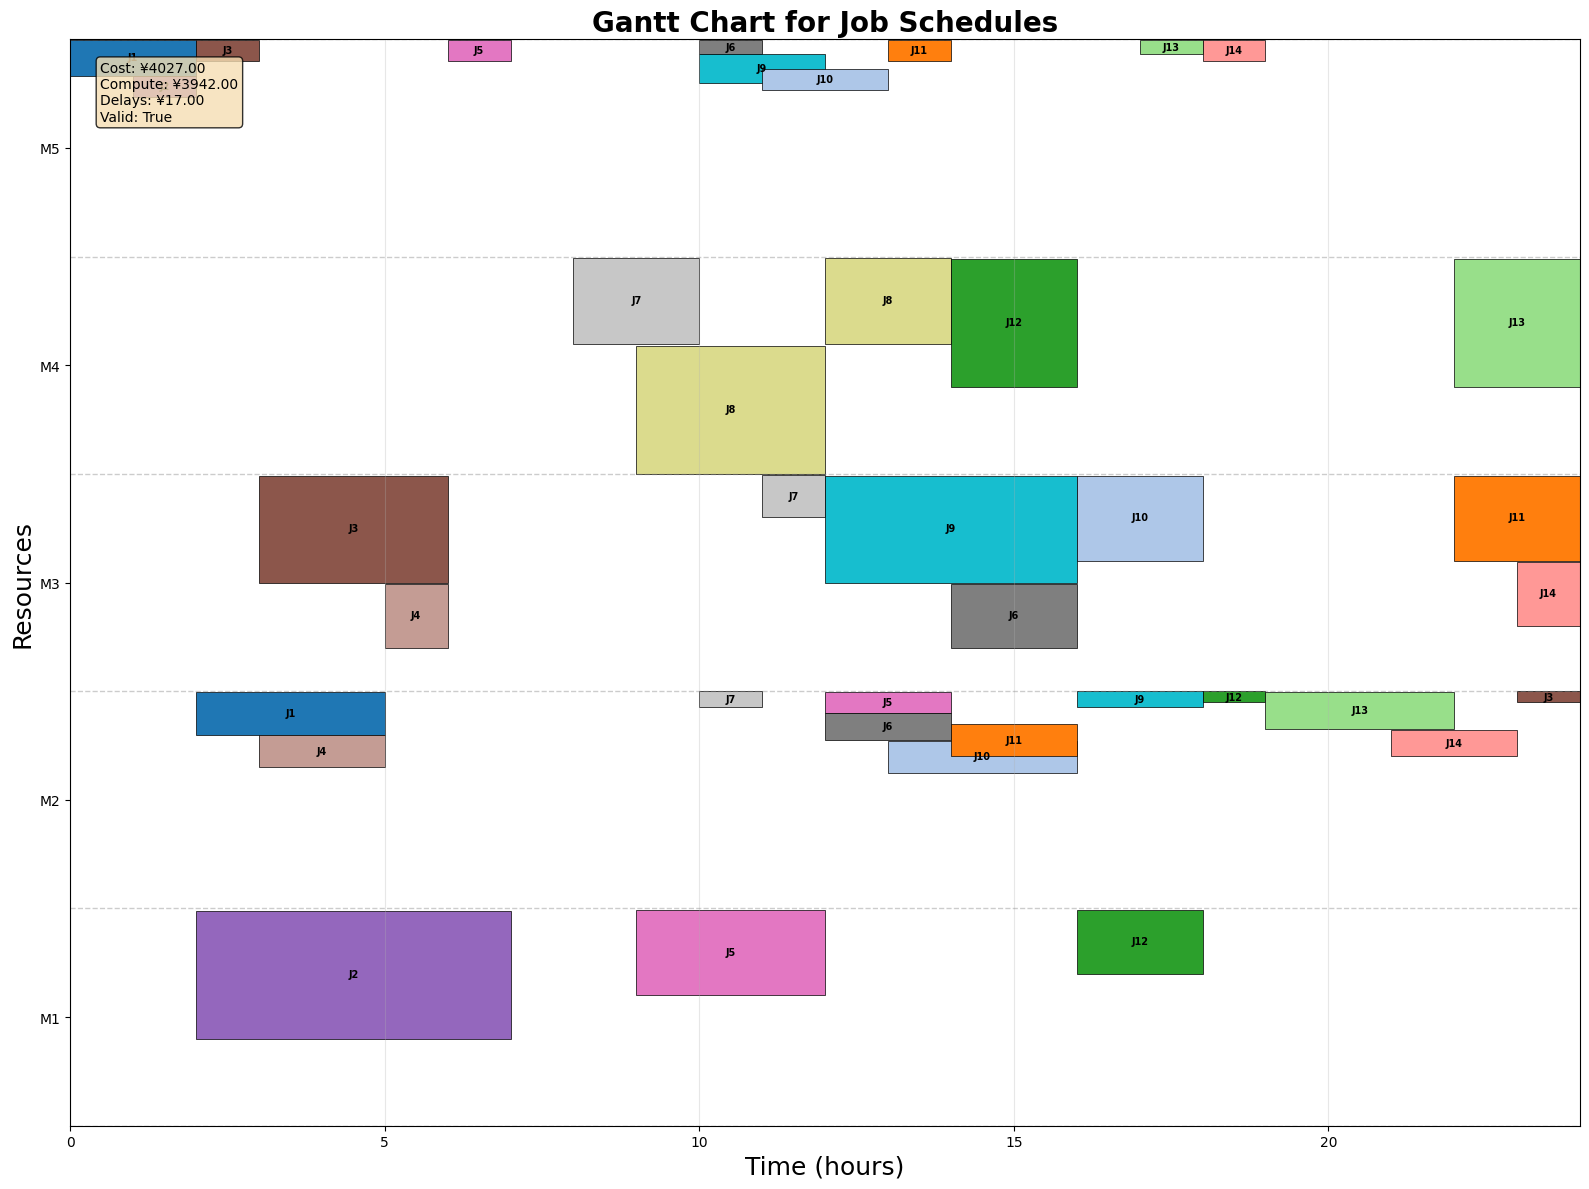

In [8]:
visualize_schedule(normal_schedule, normal_fitness, normal_inst, 
                  "")

### 4.2 Normal Day - Online Schedule

/var/folders/qy/9gjhnqpn7t78vk43mgb4_48r0000gn/T/ipykernel_43581/2549560999.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  job_cmap = cm.get_cmap('tab20')


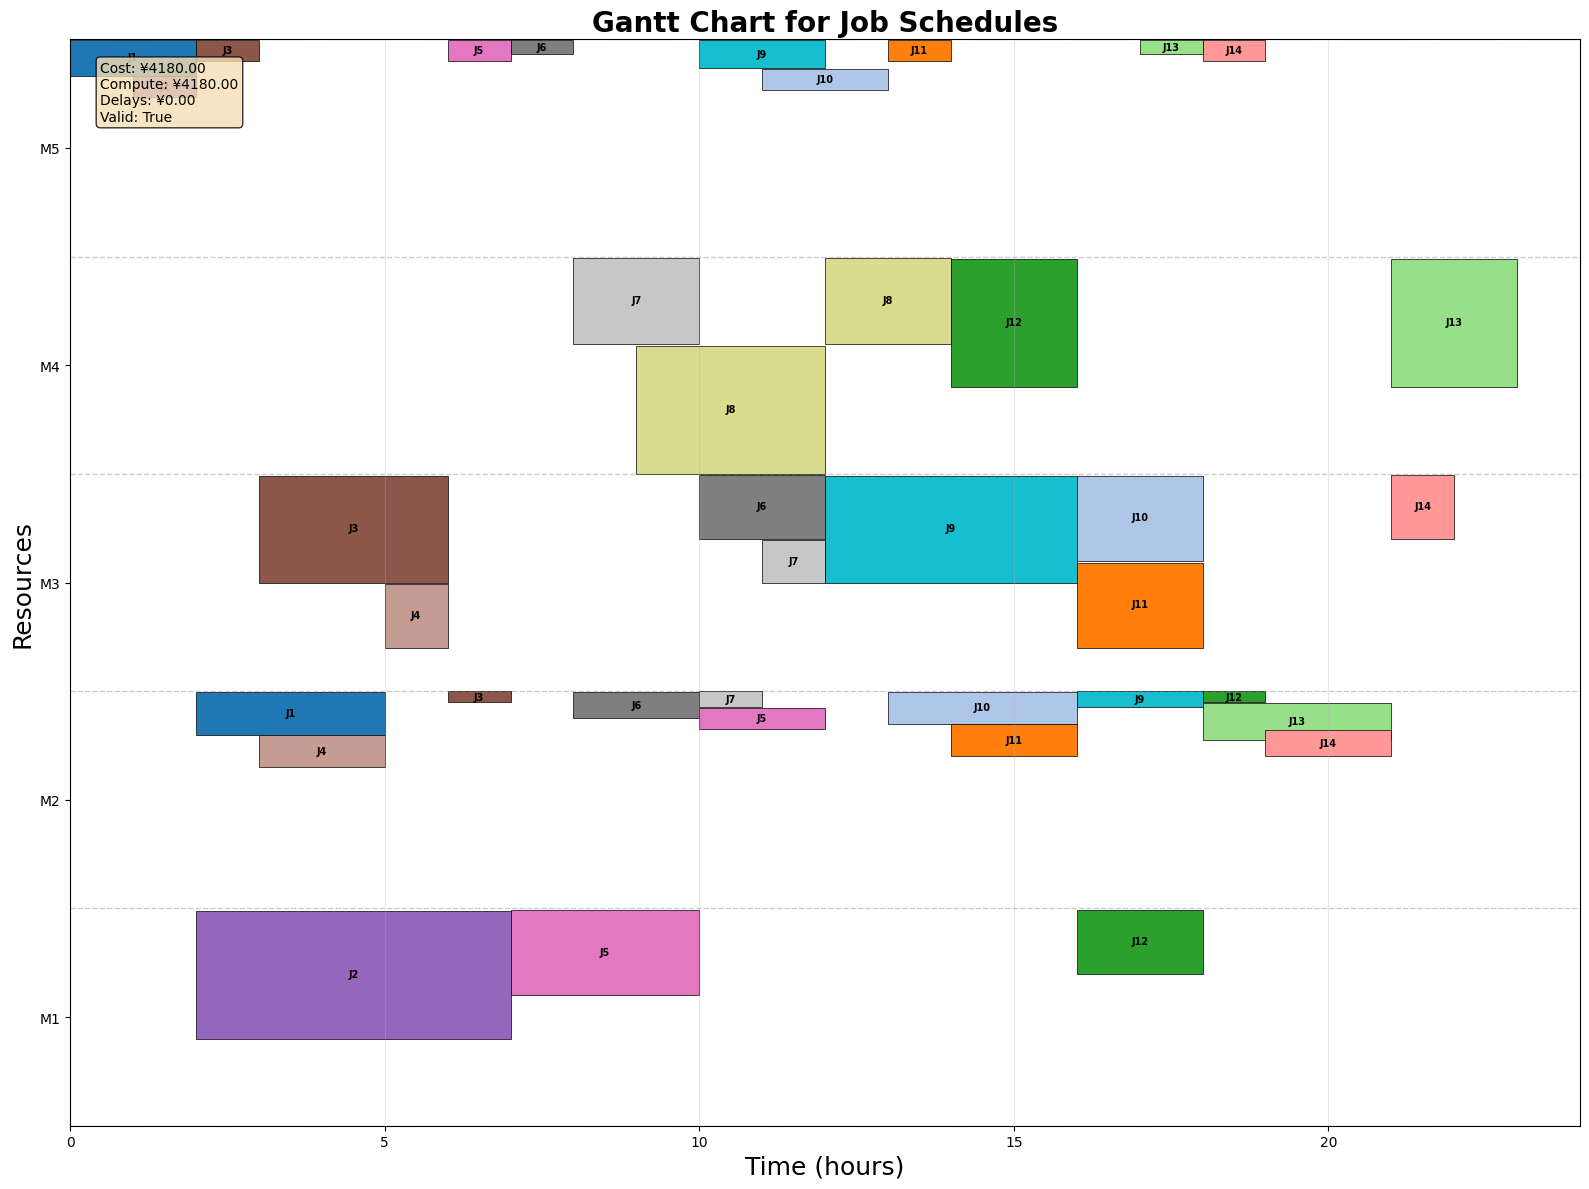

In [9]:
visualize_schedule(online_normal_sched, online_normal_fit, 
                  create_instance_from_csv("normal"),
                  "No Shock")

### 4.3 Earthquake - Clairvoyant Schedule

/var/folders/qy/9gjhnqpn7t78vk43mgb4_48r0000gn/T/ipykernel_43581/2549560999.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  job_cmap = cm.get_cmap('tab20')


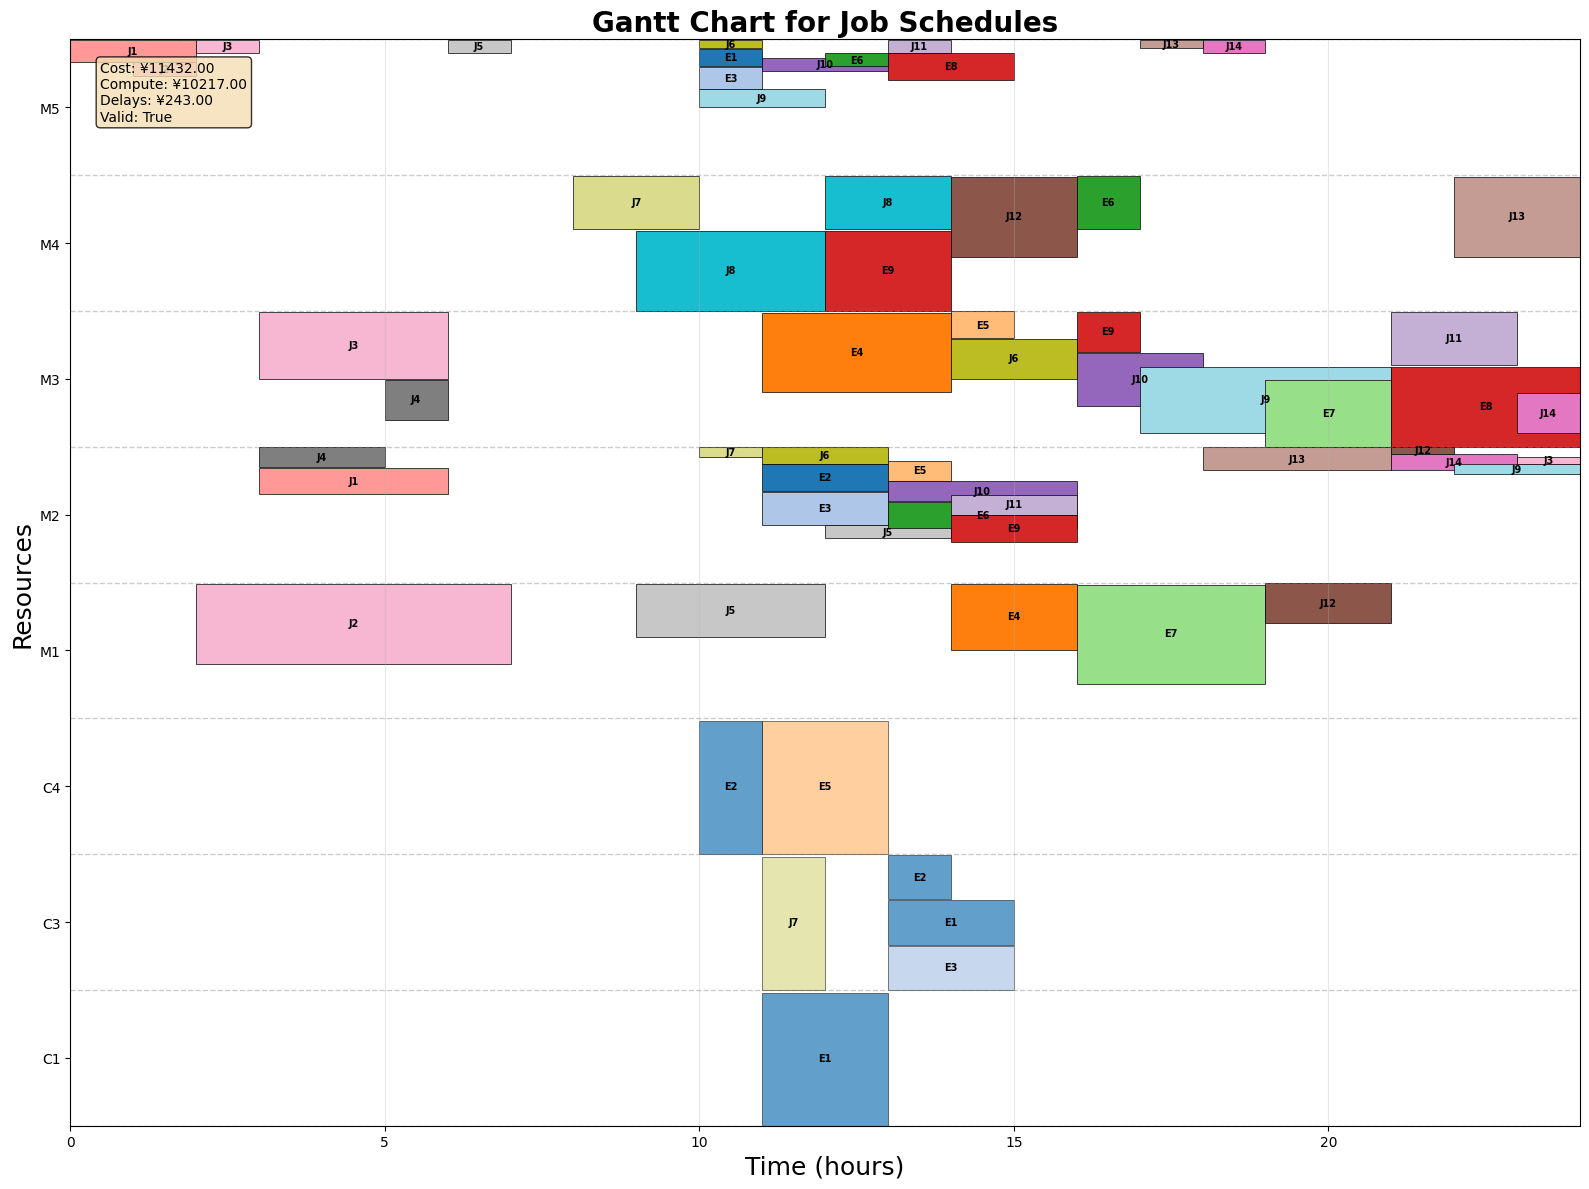

In [10]:
visualize_schedule(earthquake_schedule, earthquake_fitness, earthquake_inst,
                  "Earthquake Emergency")

### 4.4 Earthquake - Online Schedule

/var/folders/qy/9gjhnqpn7t78vk43mgb4_48r0000gn/T/ipykernel_43581/2549560999.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  job_cmap = cm.get_cmap('tab20')


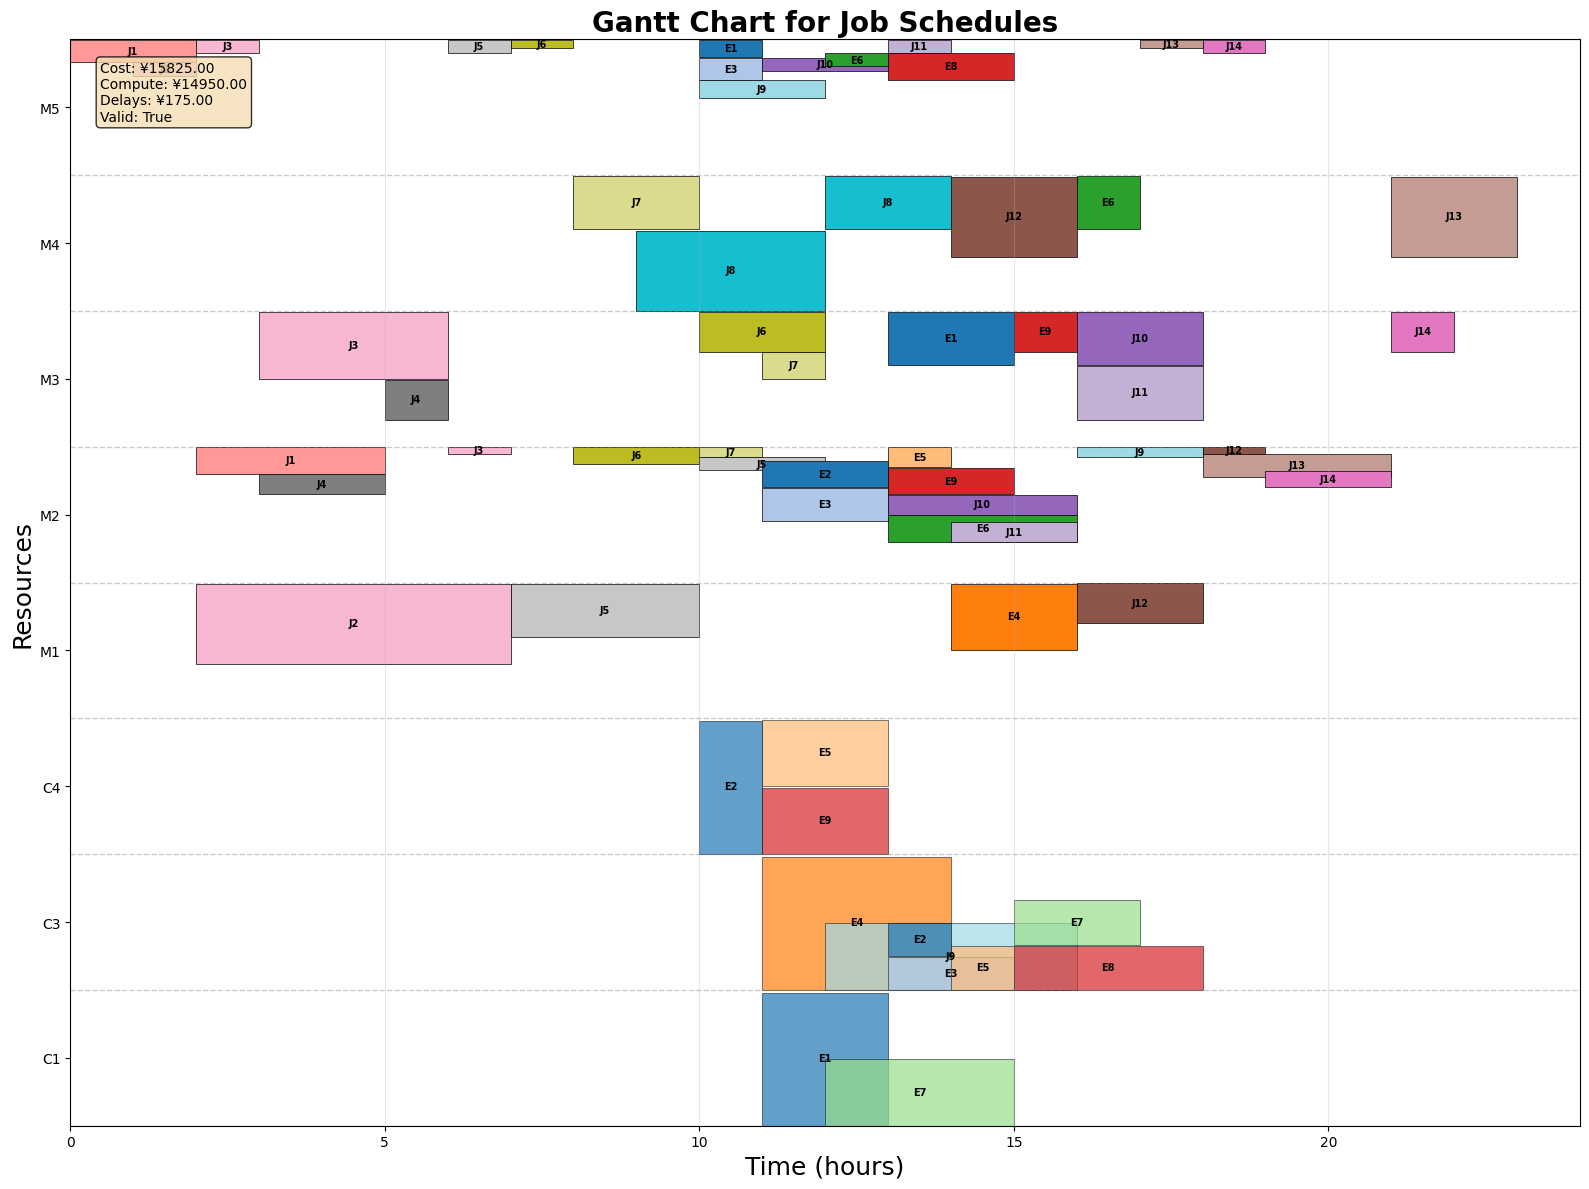

In [11]:
visualize_schedule(online_eq_sched, online_eq_fit,
                  create_instance_from_csv("earthquake", "earthquake_moderate"),
                  "Earthquake Emergency")

## 5. Machine Utilization Analysis

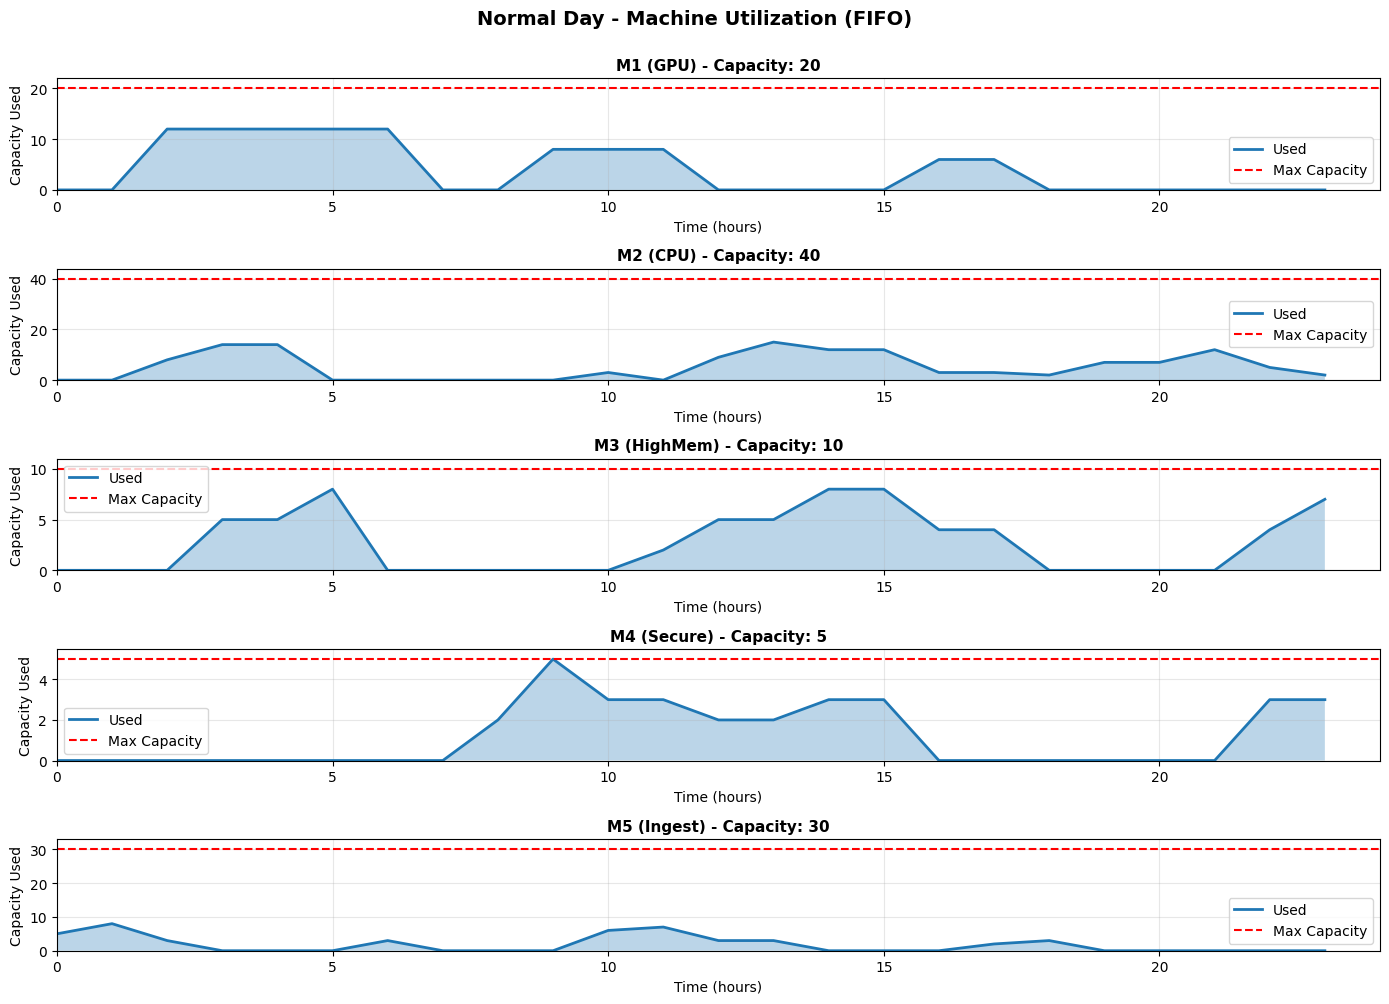

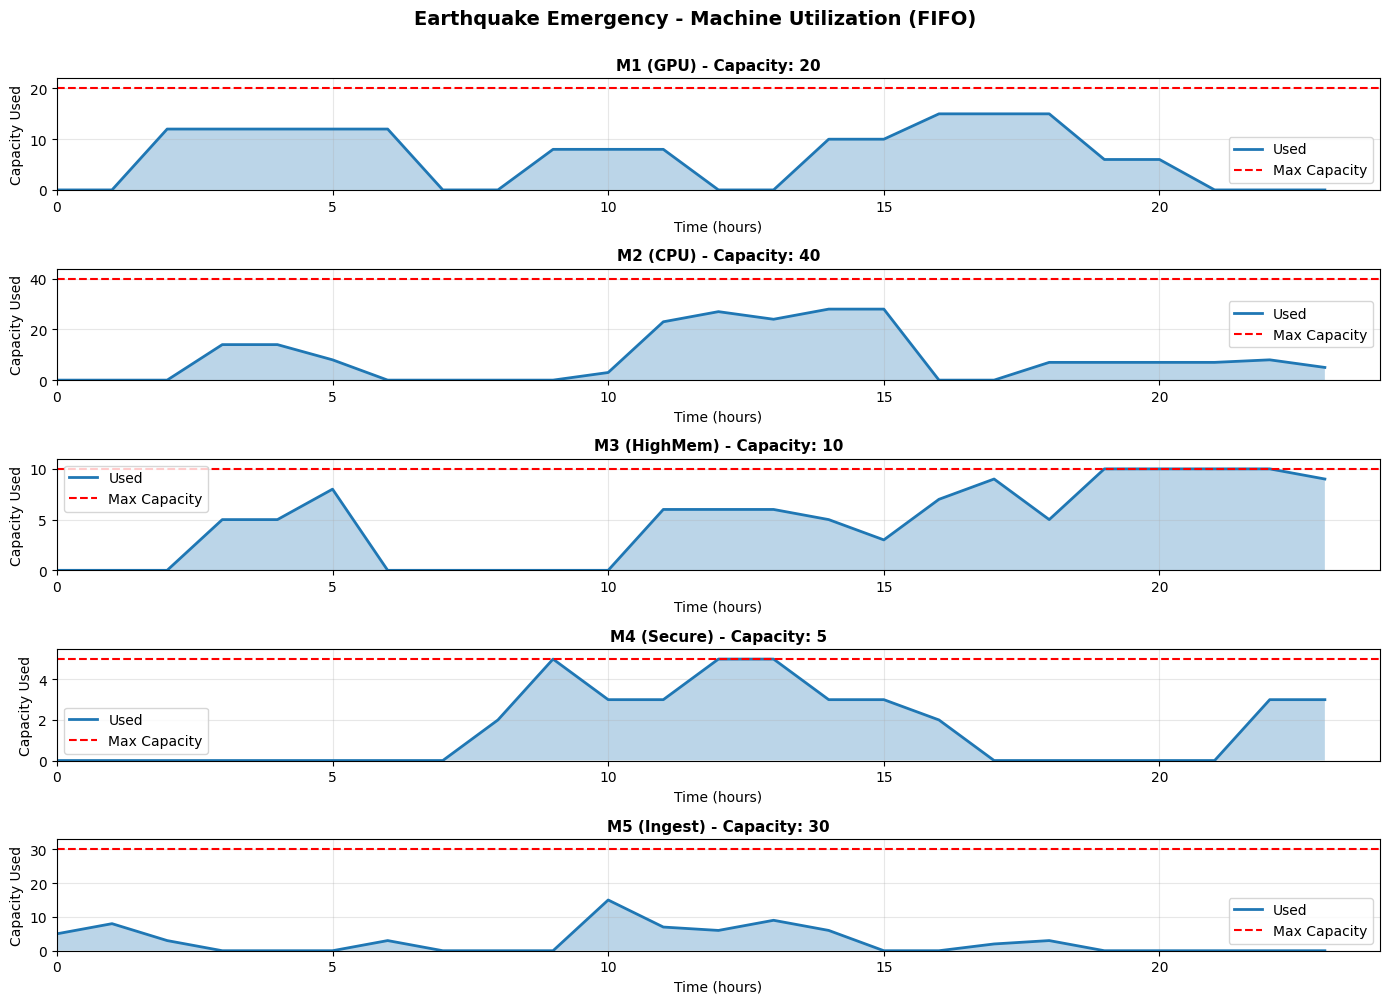

In [12]:
def analyze_utilization(schedule, inst, title="Machine Utilization"):
    """
    Analyze machine utilization over time.
    """
    # Track capacity usage
    capacity_usage = {s: [0] * inst.time_horizon for s in inst.servers}
    
    for job_id, ops in schedule.items():
        job = inst.jobs[job_id]
        for idx, op in enumerate(ops):
            server_id = op['server']
            start = op['start']
            duration = job.operations[idx].duration
            capacity_req = job.operations[idx].capacity_required
            
            for t in range(start, min(start + duration, inst.time_horizon)):
                capacity_usage[server_id][t] += capacity_req
    
    # Plot utilization for local machines
    local_servers = [s for s in inst.servers if not inst.servers[s].is_cloud]
    
    fig, axes = plt.subplots(len(local_servers), 1, figsize=(14, len(local_servers)*2))
    if len(local_servers) == 1:
        axes = [axes]
    
    for idx, server_id in enumerate(sorted(local_servers)):
        server = inst.servers[server_id]
        usage = capacity_usage[server_id]
        
        axes[idx].plot(range(inst.time_horizon), usage, linewidth=2, label='Used')
        axes[idx].axhline(y=server.capacity, color='r', linestyle='--', label='Max Capacity')
        axes[idx].fill_between(range(inst.time_horizon), 0, usage, alpha=0.3)
        
        axes[idx].set_title(f'{server_id} ({server.server_type}) - Capacity: {server.capacity}',
                          fontsize=11, fontweight='bold')
        axes[idx].set_xlabel('Time (hours)')
        axes[idx].set_ylabel('Capacity Used')
        axes[idx].legend()
        axes[idx].grid(alpha=0.3)
        axes[idx].set_xlim(0, inst.time_horizon)
        axes[idx].set_ylim(0, max(max(usage), server.capacity) * 1.1)
    
    plt.suptitle(title, fontsize=14, fontweight='bold', y=1.0)
    plt.tight_layout()
    plt.show()

# Analyze both scenarios
analyze_utilization(normal_schedule, normal_inst, "Normal Day - Machine Utilization (FIFO)")
analyze_utilization(earthquake_schedule, earthquake_inst, "Earthquake Emergency - Machine Utilization (FIFO)")

## 6. Capacity Over Time

Normal Scenario - Capacity Analysis:


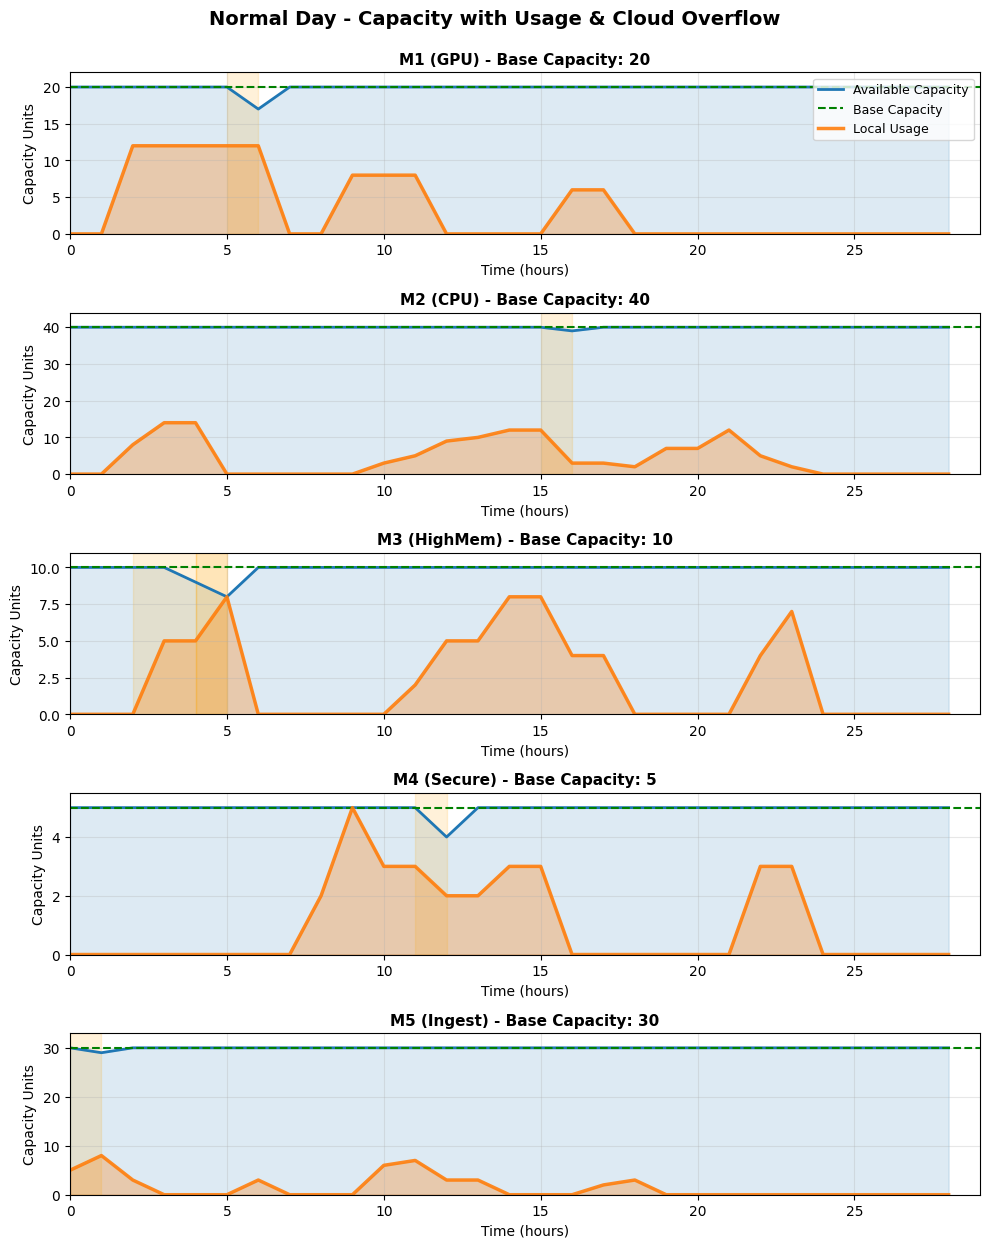


Earthquake Scenario - Capacity Analysis:


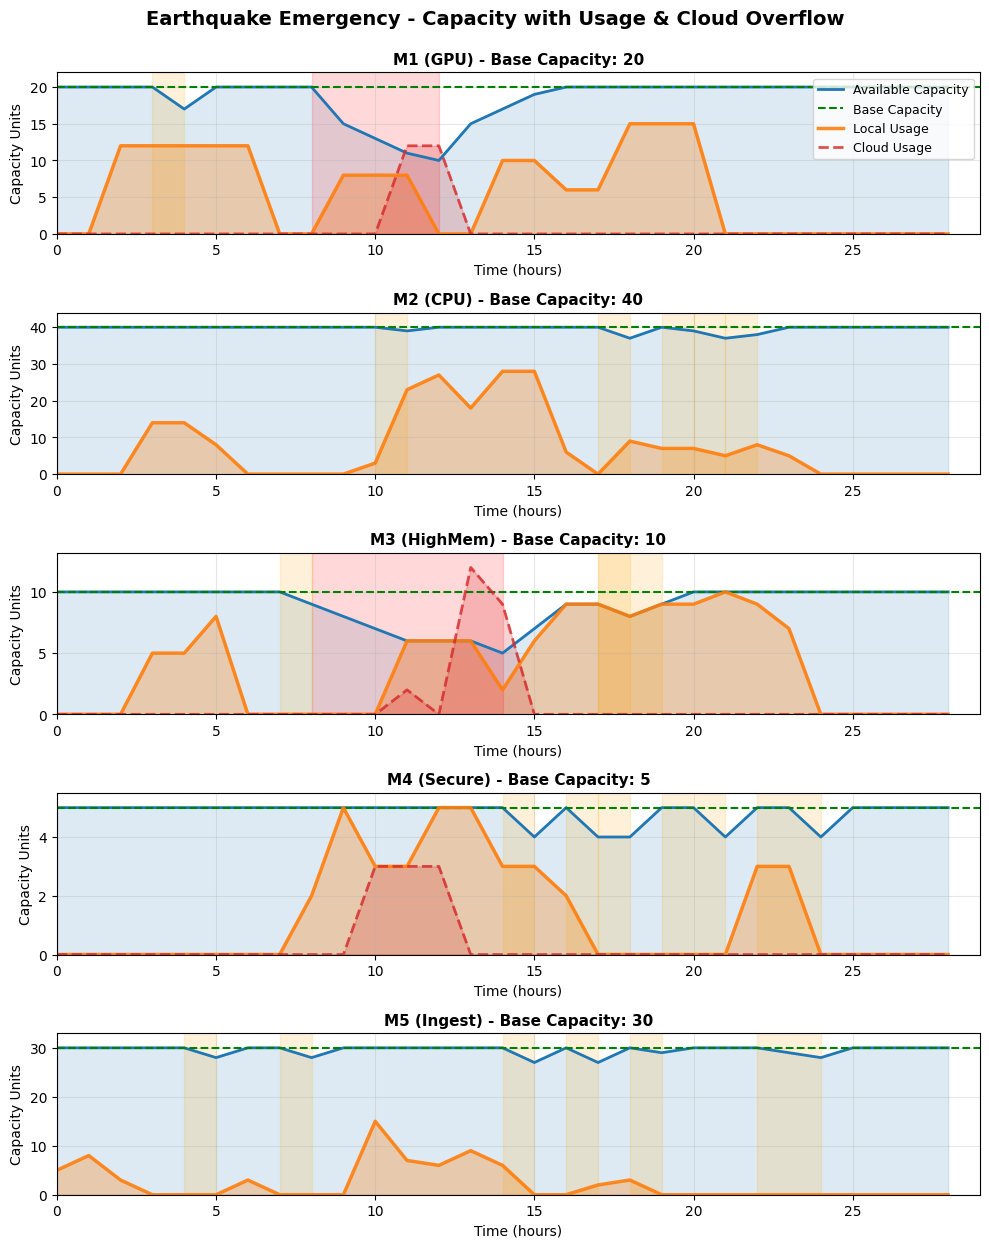

In [13]:
def plot_capacity_over_time(inst, schedule, title="Available Capacity Over Time"):
    """
    Plot how available capacity changes over time due to failures,
    along with actual usage and cloud resource usage.
    """
    import math
    
    def get_available_capacity(server_id, time):
        """Calculate available capacity considering exponential failure/recovery."""
        server = inst.servers[server_id]
        base_capacity = server.capacity
        
        if not inst.machine_failures:
            return base_capacity
        
        total_reduction = 0
        for failure in inst.machine_failures:
            if failure.machine_id != server_id:
                continue
            
            if time < failure.failure_start:
                continue
            elif time >= failure.failure_end:
                time_since_end = time - failure.failure_end
                recovery_factor = 1.0 - math.exp(-failure.recovery_rate * time_since_end)
                reduction = failure.capacity_reduction * (1.0 - recovery_factor)
                total_reduction += reduction
            else:
                time_since_start = time - failure.failure_start
                failure_factor = 1.0 - math.exp(-failure.failure_rate * time_since_start)
                reduction = failure.capacity_reduction * failure_factor
                total_reduction += reduction
        
        return max(0, base_capacity - int(total_reduction))
    
    def get_used_capacity(server_id, time):
        """Calculate used capacity at a given time from the schedule."""
        used = 0
        for job_id, ops in schedule.items():
            job = inst.jobs[job_id]
            for idx, op in enumerate(ops):
                if op['server'] == server_id:
                    start = op['start']
                    duration = job.operations[idx].duration
                    end = start + duration
                    
                    if start <= time < end:
                        used += job.operations[idx].capacity_required
        return used
    
    # Map cloud servers to local servers by type
    cloud_to_local_map = {
        'C1': 'M1',  # GPU
        'C2': 'M2',  # CPU
        'C3': 'M3',  # MEMORY
        'C4': 'M4',  # STORAGE
        'C5': 'M5'   # NETWORK
    }
    
    # Get local machines only
    local_machines = [s for s_id, s in inst.servers.items() if not s.is_cloud]
    
    if not local_machines:
        print("No local machines to plot")
        return
    
    fig, axes = plt.subplots(len(local_machines), 1, figsize=(10, len(local_machines)*2.5))
    if len(local_machines) == 1:
        axes = [axes]
    
    for idx, server in enumerate(sorted(local_machines, key=lambda s: s.id)):
        time_range = range(inst.time_horizon + 5)  # Include recovery period
        capacities = [get_available_capacity(server.id, t) for t in time_range]
        used_capacities = [get_used_capacity(server.id, t) for t in time_range]
        
        # Get cloud usage for this machine type
        cloud_server_id = None
        for cloud_id, local_id in cloud_to_local_map.items():
            if local_id == server.id:
                cloud_server_id = cloud_id
                break
        
        cloud_used = []
        if cloud_server_id and cloud_server_id in inst.servers:
            cloud_used = [get_used_capacity(cloud_server_id, t) for t in time_range]
        
        # Plot available capacity
        axes[idx].plot(time_range, capacities, linewidth=2, color='#1f77b4', 
                      label='Available Capacity', linestyle='-')
        axes[idx].axhline(y=server.capacity, color='g', linestyle='--', 
                         linewidth=1.5, label='Base Capacity')
        axes[idx].fill_between(time_range, 0, capacities, alpha=0.15, color='#1f77b4')
        
        # Plot used capacity (local)
        axes[idx].plot(time_range, used_capacities, linewidth=2.5, color='#ff7f0e', 
                      label='Local Usage', linestyle='-', alpha=0.9)
        axes[idx].fill_between(time_range, 0, used_capacities, alpha=0.3, color='#ff7f0e')
        
        # Plot cloud usage if any
        if cloud_used and any(u > 0 for u in cloud_used):
            axes[idx].plot(time_range, cloud_used, linewidth=2, color='#d62728', 
                          label=f'Cloud Usage', linestyle='--', alpha=0.8)
            axes[idx].fill_between(time_range, 0, cloud_used, alpha=0.2, color='#d62728')
        
        # Mark failure events
        if inst.machine_failures:
            for failure in inst.machine_failures:
                if failure.machine_id == server.id:
                    axes[idx].axvspan(failure.failure_start, failure.failure_end, 
                                    alpha=0.15, color='red' if not failure.is_random else 'orange')
        
        axes[idx].set_title(f'{server.id} ({server.server_type}) - Base Capacity: {server.capacity}',
                          fontsize=11, fontweight='bold')
        axes[idx].set_xlabel('Time (hours)')
        axes[idx].set_ylabel('Capacity Units')
        if idx == 0:
            axes[idx].legend(loc='upper right', fontsize=9)
        axes[idx].grid(alpha=0.3)
        axes[idx].set_xlim(0, inst.time_horizon + 5)
        
        # Set y-limit to accommodate both available capacity and usage
        max_val = max(max(capacities), max(used_capacities) if used_capacities else 0)
        if cloud_used:
            max_val = max(max_val, max(cloud_used) if cloud_used else 0)
        axes[idx].set_ylim(0, max(server.capacity, max_val) * 1.1)
    
    plt.suptitle(title, fontsize=14, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.show()

# Plot for both scenarios
print("Normal Scenario - Capacity Analysis:")
plot_capacity_over_time(normal_inst_random, normal_schedule_rf,
                       "Normal Day - Capacity with Usage & Cloud Overflow")

print("\nEarthquake Scenario - Capacity Analysis:")
plot_capacity_over_time(earthquake_inst_random, earthquake_schedule_rf,
                       "Earthquake Emergency - Capacity with Usage & Cloud Overflow")

FAILURE TIMELINE VISUALIZATIONS


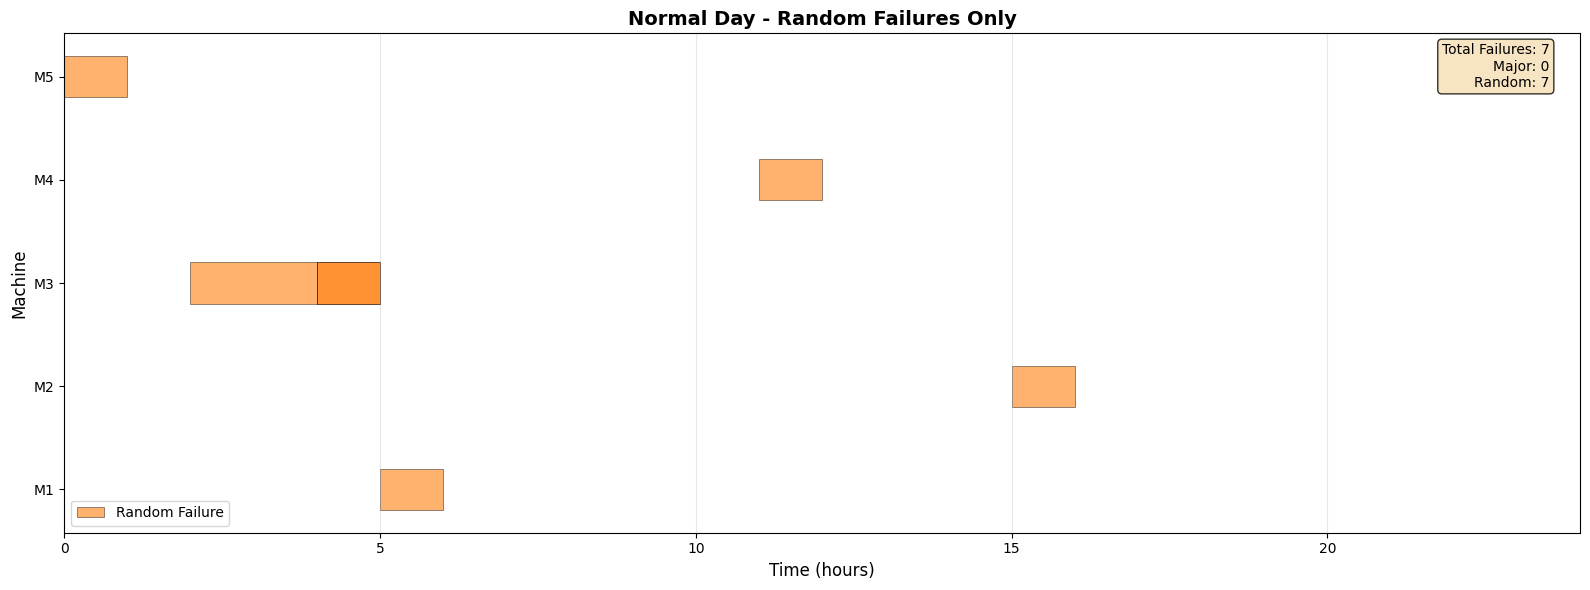

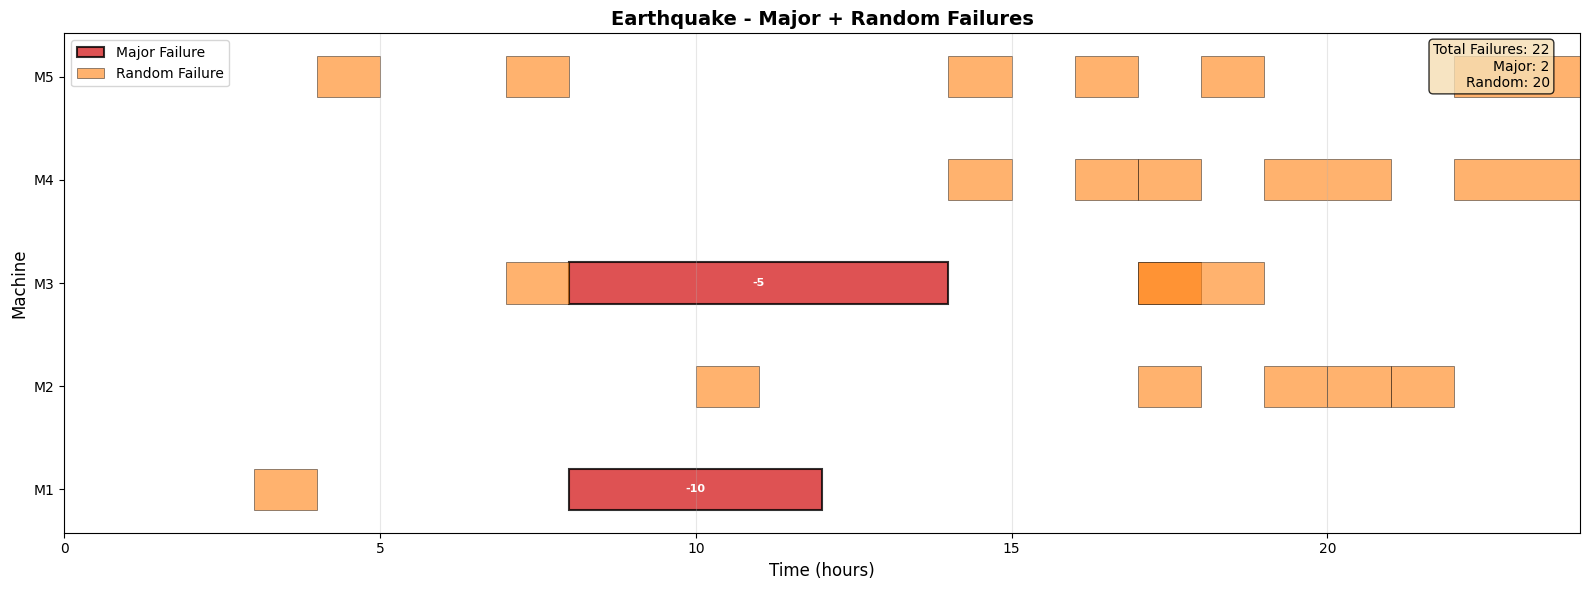

In [14]:
def visualize_failures(inst, title="Machine Failure Timeline"):
    """
    Visualize machine failures over time.
    """
    if not inst.machine_failures:
        print("No failures to visualize")
        return
    
    # Separate major and random failures
    major_failures = [f for f in inst.machine_failures if not f.is_random]
    random_failures = [f for f in inst.machine_failures if f.is_random]
    
    # Get unique machines
    machines = sorted(set(f.machine_id for f in inst.machine_failures))
    machine_to_y = {m: i for i, m in enumerate(machines)}
    
    fig, ax = plt.subplots(figsize=(16, max(6, len(machines) * 0.8)))
    
    # Plot major failures
    for failure in major_failures:
        y_pos = machine_to_y[failure.machine_id]
        duration = failure.failure_end - failure.failure_start
        ax.barh(y_pos, duration, left=failure.failure_start,
               height=0.4, color='#d62728', alpha=0.8,
               edgecolor='black', linewidth=1.5, label='Major Failure' if failure == major_failures[0] else '')
        
        # Add capacity reduction label
        ax.text(failure.failure_start + duration/2, y_pos, f'-{failure.capacity_reduction}',
               ha='center', va='center', fontsize=8, fontweight='bold', color='white')
    
    # Plot random failures
    for failure in random_failures:
        y_pos = machine_to_y[failure.machine_id]
        duration = failure.failure_end - failure.failure_start
        ax.barh(y_pos, duration, left=failure.failure_start,
               height=0.4, color='#ff7f0e', alpha=0.6,
               edgecolor='black', linewidth=0.5, label='Random Failure' if failure == random_failures[0] else '')
    
    ax.set_yticks(range(len(machines)))
    ax.set_yticklabels(machines)
    ax.set_xlabel('Time (hours)', fontsize=12)
    ax.set_ylabel('Machine', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    ax.set_xlim(0, inst.time_horizon)
    ax.legend(fontsize=10)
    
    # Add statistics
    stats_text = f"Total Failures: {len(inst.machine_failures)}\n"
    stats_text += f"Major: {len(major_failures)}\n"
    stats_text += f"Random: {len(random_failures)}"
    
    ax.text(0.98, 0.98, stats_text, transform=ax.transAxes,
           fontsize=10, verticalalignment='top', horizontalalignment='right',
           bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    plt.tight_layout()
    plt.show()

# Visualize failures for both scenarios
print("=" * 60)
print("FAILURE TIMELINE VISUALIZATIONS")
print("=" * 60)

# Normal scenario with random failures
visualize_failures(normal_inst_random, "Normal Day - Random Failures Only")

# Earthquake scenario with combined failures
visualize_failures(earthquake_inst_random, "Earthquake - Major + Random Failures")

## 7. Failure Timeline Visualization

In [15]:
print("=" * 80)
print("FINAL SUMMARY: ONLINE vs CLAIRVOYANT")
print("=" * 80)

summary_df = pd.DataFrame([
    {
        'Metric': 'Normal - Online Cost',
        'Value': f'¥{online_normal_score:.2f}'
    },
    {
        'Metric': 'Normal - Clairvoyant Cost',
        'Value': f'¥{normal_score:.2f}'
    },
    {
        'Metric': 'Normal - Competitive Ratio',
        'Value': f'{normal_ratio:.3f}x'
    },
    {
        'Metric': 'Earthquake - Online Cost',
        'Value': f'¥{online_eq_score:.2f}'
    },
    {
        'Metric': 'Earthquake - Clairvoyant Cost',
        'Value': f'¥{earthquake_score:.2f}'
    },
    {
        'Metric': 'Earthquake - Competitive Ratio',
        'Value': f'{eq_ratio:.3f}x'
    },
    {
        'Metric': 'Weighted - Online Cost',
        'Value': f'¥{online_weighted:.2f}'
    },
    {
        'Metric': 'Weighted - Clairvoyant Cost',
        'Value': f'¥{weighted_score:.2f}'
    },
    {
        'Metric': 'Weighted - Competitive Ratio',
        'Value': f'{weighted_ratio:.3f}x'
    }
])

print(summary_df.to_string(index=False))

print("\n" + "=" * 80)
print("KEY INSIGHTS")
print("=" * 80)
normal_gap = (online_normal_score - normal_score) / normal_score * 100 if normal_score > 0 else 0
eq_gap = (online_eq_score - earthquake_score) / earthquake_score * 100 if earthquake_score > 0 else 0
weighted_gap = (online_weighted - weighted_score) / weighted_score * 100 if weighted_score > 0 else 0

print(f"\n✓ Online vs Clairvoyant competitive ratio: {weighted_ratio:.3f}x")
print(f"✓ Normal day gap: {normal_gap:.1f}%")
print(f"✓ Earthquake scenario gap: {eq_gap:.1f}%")
print(f"\n✓ Price of being online (no future knowledge): ¥{online_weighted - weighted_score:.2f}")
print(f"  - Normal scenario: ¥{online_normal_score - normal_score:.2f}")
print(f"  - Earthquake scenario: ¥{online_eq_score - earthquake_score:.2f}")

print("\n" + "=" * 80)
print("RANDOM FAILURE FEATURE")
print("=" * 80)
print(f"✓ Random failures simulate realistic operational issues")
print(f"✓ Small capacity reductions (1-3 units, <15% of capacity)")
print(f"✓ Short duration (1-2 hours) with fast recovery")
print(f"✓ Exponential inter-arrival times (configurable MTBF)")
print(f"✓ Can be enabled/disabled for testing")
print(f"✓ Cost impact: {weighted_impact:.2f}% (realistic noise level)")

FINAL SUMMARY: ONLINE vs CLAIRVOYANT
                        Metric     Value
          Normal - Online Cost  ¥4180.00
     Normal - Clairvoyant Cost  ¥4027.00
    Normal - Competitive Ratio    1.038x
      Earthquake - Online Cost ¥15825.00
 Earthquake - Clairvoyant Cost ¥11432.00
Earthquake - Competitive Ratio    1.384x
        Weighted - Online Cost  ¥6509.00
   Weighted - Clairvoyant Cost  ¥5508.00
  Weighted - Competitive Ratio    1.182x

KEY INSIGHTS

✓ Online vs Clairvoyant competitive ratio: 1.182x
✓ Normal day gap: 3.8%
✓ Earthquake scenario gap: 38.4%

✓ Price of being online (no future knowledge): ¥1001.00
  - Normal scenario: ¥153.00
  - Earthquake scenario: ¥4393.00

RANDOM FAILURE FEATURE
✓ Random failures simulate realistic operational issues
✓ Small capacity reductions (1-3 units, <15% of capacity)
✓ Short duration (1-2 hours) with fast recovery
✓ Exponential inter-arrival times (configurable MTBF)
✓ Can be enabled/disabled for testing
✓ Cost impact: 0.76% (realistic no